# 03 · Ablations: regime dummies, transfer, conflict features, FX target, Chronos

Reads only generated results files. Each panel shows seed-mean test MASE for the two arms of a paired comparison;
verdicts (preregistered, Holm where stated) are printed below each figure.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load = lambda p: json.loads((ROOT / p).read_text())
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})

In [2]:
def paired_plot(cells, arms, label, title):
    fig, ax = plt.subplots(figsize=(10, 3.6))
    x = np.arange(len(cells))
    for j, arm in enumerate(arms):
        ax.bar(x + (j - 0.5) * 0.38, [np.mean([s[arm]["mase"] for s in c["seeds"]]) for c in cells], 0.38, label=arm)
    ax.axhline(1, color="k", ls="--", lw=1); ax.set_xticks(x, [label(c) for c in cells], rotation=45, fontsize=8)
    ax.set_ylabel("test MASE"); ax.set_title(title); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

## 4.4 Regime dummies (with vs without; folds 4–5 and main split)

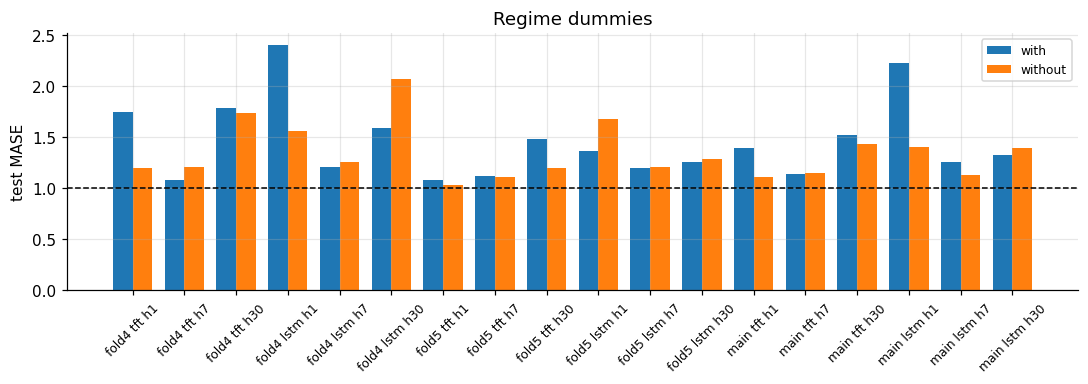

real regime_2 = 1 training rows: {'fold4': 21, 'fold5': 50, 'main': 0}


,where,model,h,verdict_absolute_holm,verdict_squared_holm
0,fold4,tft,1,regime dummies hurt,no consistent difference
1,fold4,tft,7,no consistent difference,no consistent difference
2,fold4,tft,30,no consistent difference,no consistent difference
3,fold4,lstm,1,no consistent difference,no consistent difference
4,fold4,lstm,7,no consistent difference,no consistent difference
5,fold4,lstm,30,no consistent difference,no consistent difference
6,fold5,tft,1,no consistent difference,no consistent difference
7,fold5,tft,7,no consistent difference,no consistent difference
8,fold5,tft,30,no consistent difference,no consistent difference
9,fold5,lstm,1,no consistent difference,no consistent difference


In [3]:
reg = load("results/regime/regime_results.json")
paired_plot(reg["cells"], ["with", "without"], lambda c: f"{c['where']} {c['model']} h{c['h']}", "Regime dummies")
print("real regime_2 = 1 training rows:", reg["real_regime2_train_rows"])
pd.DataFrame([{k: c[k] for k in ("where", "model", "h", "verdict_absolute_holm", "verdict_squared_holm")} for c in reg["cells"]])

## 4.5 Global → Sudan transfer vs from scratch (18 shared inputs)

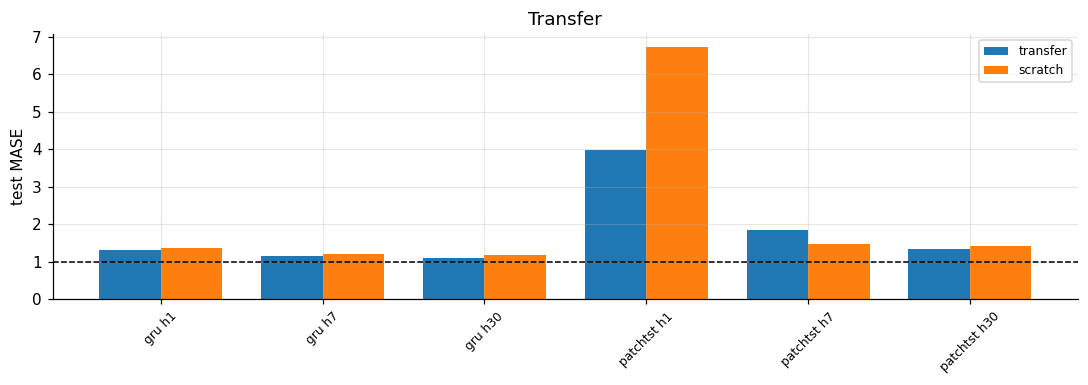

,model,h,frozen,frozen share %,verdict abs (Holm)
0,gru,1,gru_1,34.6,no consistent difference
1,gru,7,gru_1,34.5,no consistent difference
2,gru,30,gru_1,34.2,no consistent difference
3,patchtst,1,patch_embed,1.8,no consistent difference
4,patchtst,7,patch_embed,1.0,no consistent difference
5,patchtst,30,patch_embed,0.4,no consistent difference


In [4]:
tr = load("results/transfer/transfer_results.json")
paired_plot(tr["cells"], ["transfer", "scratch"], lambda c: f"{c['model']} h{c['h']}", "Transfer")
pd.DataFrame([{"model": c["model"], "h": c["h"], "frozen": c["seeds"][0]["frozen_layer"],
               "frozen share %": round(100 * c["seeds"][0]["n_params_finetune"]["non_trainable"]
                                       / c["seeds"][0]["n_params_finetune"]["total"], 1),
               "verdict abs (Holm)": c["verdict_absolute_holm"]} for c in tr["cells"]])

## 4.3 ACLED conflict features (main split, lags 1–3)

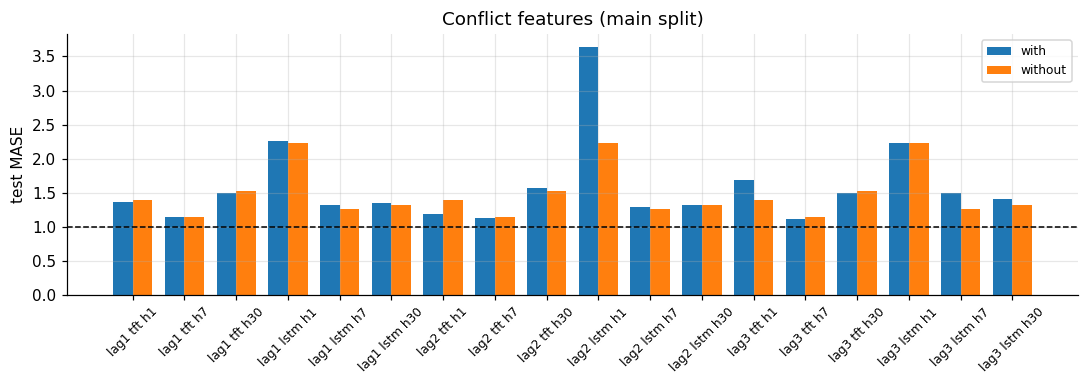

lag selected on validation: 2 {'1': 1.0090959864357438, '2': 0.9865704854605833, '3': 1.0261291150563363}


,lag,model,h,verdict_absolute,verdict_absolute_holm
0,1,tft,1,no consistent difference,no consistent difference
1,1,tft,7,no consistent difference,no consistent difference
2,1,tft,30,no consistent difference,no consistent difference
3,1,lstm,1,no consistent difference,no consistent difference
4,1,lstm,7,no consistent difference,no consistent difference
5,1,lstm,30,no consistent difference,no consistent difference
6,2,tft,1,no consistent difference,no consistent difference
7,2,tft,7,no consistent difference,no consistent difference
8,2,tft,30,no consistent difference,no consistent difference
9,2,lstm,1,no consistent difference,no consistent difference


In [5]:
ac = load("results/acled/acled_results.json")
paired_plot(ac["main"], ["with", "without"], lambda c: f"lag{c['lag']} {c['model']} h{c['h']}", "Conflict features (main split)")
print("lag selected on validation:", ac["lag_selection"]["selected_lag"], ac["lag_selection"]["mean_ratio"])
pd.DataFrame([{k: c[k] for k in ("lag", "model", "h", "verdict_absolute", "verdict_absolute_holm")} for c in ac["main"]])

## 4.7 FX rate as the target, and 4.2 Chronos zero-shot

In [6]:
fx = load("results/fx_target/fx_results.json")
rows = [{"setting": s, "model": m, "FX route MASE": np.mean([x["fx"]["mase"] for x in c["seeds"]]),
         "direct MASE": np.mean([x["direct"]["mase"] for x in c["seeds"]]), "verdict vs direct": c["verdict_vs_direct_absolute"]}
        for s, r in fx["results"].items() for m, c in r.items()]
print(fx["summary"])
pd.DataFrame(rows).round(3)

{'n_cells': 18, 'fx_better_abs': 0, 'fx_worse_abs': 2, 'answer': 'no consistent difference', 'beats_persistence_abs': 0, 'worse_than_persistence_abs': 16}


,setting,model,FX route MASE,direct MASE,verdict vs direct
0,sudan_h1,lstm,2.577,2.228,no significant difference
1,sudan_h1,gru,6.612,2.440,FX route worse
2,sudan_h1,tsmixer,4.616,3.089,FX route worse
3,sudan_h1,patchtst,25.451,12.761,no significant difference
4,sudan_h1,tft,2.063,1.392,no significant difference
5,sudan_h1,ensemble,2.090,1.512,no significant difference
6,sudan_h7,lstm,1.242,1.259,no significant difference
7,sudan_h7,gru,2.431,2.054,no significant difference
8,sudan_h7,tsmixer,2.795,2.375,no significant difference
9,sudan_h7,patchtst,3.289,2.703,no significant difference


In [7]:
ch = load("results/chronos/chronos_results.json")
pd.DataFrame([{"setting": s, "size": z, "test MASE": np.mean([x["test"]["mase"] for x in c["seeds"]]),
               "verdict abs": c["test"]["verdict_absolute"]} for s, r in ch["results"].items() for z, c in r["sizes"].items()]).round(3)

,setting,size,test MASE,verdict abs
0,sudan_h1,mini,1.379,worse
1,sudan_h1,small,1.377,worse
2,sudan_h7,mini,1.078,worse
3,sudan_h7,small,1.079,worse
4,sudan_h30,mini,1.031,no significant difference
5,sudan_h30,small,1.045,worse
6,global_h1,mini,1.056,worse
7,global_h1,small,1.062,worse
8,global_h7,mini,1.041,worse
9,global_h7,small,1.049,worse
